[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch29_LabCh29_Generative_Models.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 29: The Generative Family: GANs, Diffusion and Friends** (Part VI: Imagining).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=29](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=29)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# Lab Ch29 - Generative Models: Diffusion and a Tiny GAN
## Destroy digits with noise, teach a network to undo it, and watch a forger chase a detective

This lab goes with **Chapter 29** of *The Why Book of Deep Learning*.

A generative model does not answer "which class is this?". It answers "make me another one". This lab builds
the two families that dominated image generation, at a size a laptop can train in a few minutes:

* **Diffusion.** Add Gaussian noise to MNIST digits, a little at a time, until nothing is left. Then train a
  small network to look at a noisy digit, told *how* noisy it is, and guess the noise. Run that guess
  backwards from pure static and digits (rough ones) appear.
* **A GAN.** A generator turns random numbers into 2-D points; a discriminator tries to tell its points from
  real ones drawn from a ring of 8 blobs. We watch whether the generator learns all 8 blobs or only a few.

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Write the forward (noising) process in one line and jump straight to any step | Steps 3 and 4 |
| Read a noise schedule through its signal-to-noise ratio | Step 4 |
| Count the parameters of a small time-conditioned U-Net by hand | Step 6 |
| Train a noise predictor with plain MSE, and read its loss | Steps 7 and 8 |
| See why one big denoising jump gives a blur and many small ones give a digit | Step 9 |
| Sample from the reverse process, and judge the result honestly | Step 10 |
| Train a GAN with a custom loop, measure mode coverage, and provoke mode collapse | Steps 11 to 13b |
| Explain classifier-free guidance as one line of arithmetic | Step 14 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**.

> **Runtime:** a few minutes on a laptop CPU. To keep it short the denoiser trains on **12,000** digits for
> **8** epochs, and the GAN for **3,000** small steps. Real diffusion models train for hundreds of thousands of
> steps on millions of images. Expect rough digits, not pretty ones; the point is to see the mechanism work.

---
## Step 1 - Imports and one seed

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(29)
rng = np.random.default_rng(29)
np.set_printoptions(precision=4, suppress=True)
T0 = time.time()
print("TensorFlow:", tf.__version__, " Keras:", keras.__version__)

TensorFlow: 2.21.0  Keras: 3.14.1


---
## Step 2 - Load MNIST and scale to [-1, 1]

Diffusion models usually scale pixels to **[-1, 1]**, not [0, 1], so that the clean data and the Gaussian
noise (mean 0, standard deviation 1) live on the same scale and are centred the same way.

> **Predict:** after scaling, what value does the black background have?

In [2]:
(x_train_full, _), (x_test, _) = keras.datasets.mnist.load_data()
N_TRAIN = 12_000                                     # raise to 60_000 for a real run
x_train = x_train_full[:N_TRAIN].astype("float32") / 127.5 - 1.0
x_test = x_test[:1000].astype("float32") / 127.5 - 1.0
x_train = x_train[..., None]
x_test = x_test[..., None]
print("train:", x_train.shape, " test:", x_test.shape)
print("pixel range:", x_train.min(), "to", x_train.max())
print(f"share of pixels that are background (-1): {np.mean(x_train == -1):.1%}")

train: (12000, 28, 28, 1)  test: (1000, 28, 28, 1)
pixel range: -1.0 to 1.0
share of pixels that are background (-1): 80.8%


---
## Step 3 - The noise schedule

The forward process takes **T = 100** steps. At step t it shrinks the image a little and adds a little fresh
Gaussian noise. How much is set by a schedule of small numbers **beta_t**, rising in a straight line from
0.0001 to 0.12.

The useful fact: you never have to run the 100 steps one by one. Multiplying all the "keep" factors
(1 - beta) up to step t gives **alpha_bar_t**, and then in one line

`x_t = sqrt(alpha_bar_t) * x_0 + sqrt(1 - alpha_bar_t) * noise`

> **Predict:** alpha_bar starts near 1 (all signal). Roughly what is it at the last step: 0.5, 0.1, or
> close to 0?

In [3]:
T = 100
betas = np.linspace(1e-4, 0.12, T).astype("float32")      # beta_1 ... beta_T
alphas = 1.0 - betas
alpha_bar = np.cumprod(alphas)                             # alpha_bar_1 ... alpha_bar_T
for t in [1, 10, 25, 50, 75, 100]:
    ab = alpha_bar[t - 1]
    print(f"t = {t:3d}   alpha_bar = {ab:.4f}   signal weight sqrt(ab) = {np.sqrt(ab):.3f}"
          f"   noise weight sqrt(1-ab) = {np.sqrt(1 - ab):.3f}")

def q_sample(x0, t, noise):
    """Jump straight to step t (t is an integer array, 1..T)."""
    ab = alpha_bar[t - 1].reshape(-1, 1, 1, 1)
    return np.sqrt(ab) * x0 + np.sqrt(1.0 - ab) * noise

t =   1   alpha_bar = 0.9999   signal weight sqrt(ab) = 1.000   noise weight sqrt(1-ab) = 0.010
t =  10   alpha_bar = 0.9458   signal weight sqrt(ab) = 0.973   noise weight sqrt(1-ab) = 0.233
t =  25   alpha_bar = 0.6911   signal weight sqrt(ab) = 0.831   noise weight sqrt(1-ab) = 0.556
t =  50   alpha_bar = 0.2189   signal weight sqrt(ab) = 0.468   noise weight sqrt(1-ab) = 0.884
t =  75   alpha_bar = 0.0310   signal weight sqrt(ab) = 0.176   noise weight sqrt(1-ab) = 0.984
t = 100   alpha_bar = 0.0019   signal weight sqrt(ab) = 0.044   noise weight sqrt(1-ab) = 0.999


### Why we see this

By step 100 only about **4%** of the original image is left in the mix (signal weight 0.044) and the rest is
noise. That is what lets sampling *start* from pure noise: at the last step a noised digit and pure static
are nearly the same thing.

---
## Step 4 - Watch one digit dissolve, and measure the signal-to-noise ratio

The **signal-to-noise ratio** at step t is alpha_bar / (1 - alpha_bar): the power of what is left of the
image divided by the power of the noise. We print it in decibels (10 log10), the unit engineers use.

> **Predict:** at which step does the digit stop being readable to *you*? Write down a number before you look.

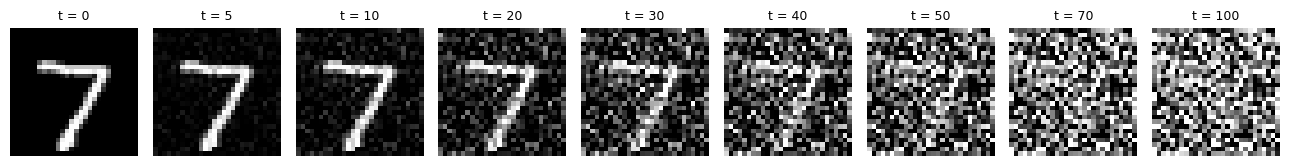

t =   1   SNR =   9997.341   =   40.0 dB
t =   5   SNR =     78.650   =   19.0 dB
t =  10   SNR =     17.453   =   12.4 dB
t =  20   SNR =      3.794   =    5.8 dB
t =  30   SNR =      1.409   =    1.5 dB
t =  40   SNR =      0.616   =   -2.1 dB
t =  50   SNR =      0.280   =   -5.5 dB
t =  70   SNR =      0.051   =  -12.9 dB
t = 100   SNR =      0.002   =  -27.2 dB
first step where noise outweighs signal (SNR < 1): 35


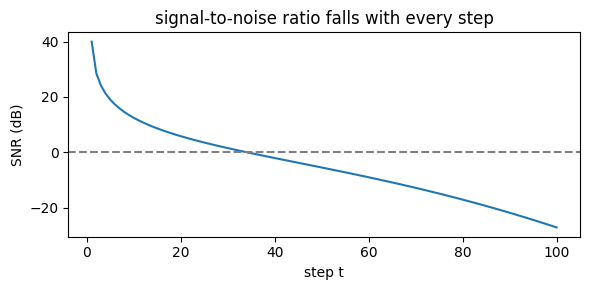

In [4]:
x0 = x_test[:1]
noise = rng.standard_normal(x0.shape).astype("float32")
show_t = [0, 5, 10, 20, 30, 40, 50, 70, 100]
strip = [x0[0, :, :, 0] if t == 0 else q_sample(x0, np.array([t]), noise)[0, :, :, 0] for t in show_t]
plt.figure(figsize=(13, 1.8))
for i, (t, img) in enumerate(zip(show_t, strip)):
    ax = plt.subplot(1, len(show_t), i + 1)
    ax.imshow(img, cmap="gray", vmin=-1, vmax=1); ax.axis("off"); ax.set_title(f"t = {t}", fontsize=9)
plt.tight_layout(); plt.show()

snr = alpha_bar / (1.0 - alpha_bar)
snr_db = 10 * np.log10(snr)
for t in [1, 5, 10, 20, 30, 40, 50, 70, 100]:
    print(f"t = {t:3d}   SNR = {snr[t - 1]:10.3f}   = {snr_db[t - 1]:6.1f} dB")
t_cross = int(np.argmax(snr < 1.0)) + 1
print("first step where noise outweighs signal (SNR < 1):", t_cross)

plt.figure(figsize=(6, 3))
plt.plot(range(1, T + 1), snr_db); plt.axhline(0, color="grey", ls="--")
plt.xlabel("step t"); plt.ylabel("SNR (dB)"); plt.title("signal-to-noise ratio falls with every step")
plt.tight_layout(); plt.show()

### Why we see this

The SNR falls by about **67 dB** over the 100 steps: from about 10,000 to about 1/500. Most people stop
reading the digit somewhere around step 30 to 40, close to where the SNR crosses 1 (0 dB). Notice that the
curve is steep at the start and end and gentler in the middle: a linear beta schedule spends many steps where
the picture is already almost gone. Better schedules (the "cosine" schedule) spread the steps more evenly.

---
## Step 5 - What the network will be trained to do

Take a clean digit, pick a random step t, draw noise, make x_t with `q_sample`. Hand the network **x_t and
t** and ask it for **the noise**. The loss is the mean squared error between the true noise and its guess.

That is a denoising autoencoder (Chapter 27) with one extra input: how noisy the picture is.

> **Predict:** a lazy network that always answers "zero noise" gets what MSE? (The noise has variance 1.)

In [5]:
def sinusoidal(t, dim=32):
    """The standard sine/cosine embedding of an integer step, like a transformer's positions."""
    half = dim // 2
    freqs = np.exp(-np.log(1000.0) * np.arange(half) / half)
    ang = np.asarray(t, dtype="float32")[:, None] * freqs[None, :]
    return np.concatenate([np.sin(ang), np.cos(ang)], axis=1).astype("float32")

TEMB = sinusoidal(np.arange(T + 1))                         # one row per step, (101, 32)
print("time-embedding table:", TEMB.shape)
eps = rng.standard_normal((10_000, 28, 28, 1)).astype("float32")
print(f"MSE of always answering zero: {np.mean(eps ** 2):.3f}")

time-embedding table: (101, 32)
MSE of always answering zero: 0.999


### Why we see this

Guessing zero scores about **1.0**, because that is the variance of the noise. Every number below 1 in the
training log is something the network has learnt about digits. Unlike a GAN, this loss means something on its
own, and it goes down smoothly: the main practical reason diffusion displaced GANs.

---
## Step 6 - A tiny U-Net that knows the time, with a hand count

Two downsampling stages (28 → 14 → 7), two upsampling stages back to 28, and skip connections that carry fine
detail straight across (the U-Net of Chapter 27). The step t enters as its 32-number embedding; a small Dense
layer turns it into a per-channel shift that is **added** to the feature maps at each resolution.

> **Predict:** which single layer holds the most parameters? (Look for the widest input.)

In [6]:
def tiny_unet():
    x_in = layers.Input(shape=(28, 28, 1), name="x_t")
    t_in = layers.Input(shape=(32,), name="t_embedding")
    e = layers.Dense(64, activation="swish", name="t_mlp")(t_in)

    def add_time(h, ch, name):
        shift = layers.Reshape((1, 1, ch))(layers.Dense(ch, name=name)(e))
        return layers.Add()([h, shift])

    h1 = layers.Conv2D(32, 3, padding="same", activation="swish", name="c28a")(x_in)
    h1 = add_time(h1, 32, "t28")
    h1 = layers.Conv2D(32, 3, padding="same", activation="swish", name="c28b")(h1)
    d1 = layers.Conv2D(64, 3, strides=2, padding="same", activation="swish", name="down14")(h1)
    d1 = add_time(d1, 64, "t14")
    d1 = layers.Conv2D(64, 3, padding="same", activation="swish", name="c14")(d1)
    d2 = layers.Conv2D(64, 3, strides=2, padding="same", activation="swish", name="down7")(d1)
    d2 = add_time(d2, 64, "t7")
    d2 = layers.Conv2D(64, 3, padding="same", activation="swish", name="c7")(d2)
    u1 = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="swish", name="up14")(d2)
    u1 = layers.Concatenate()([u1, d1])                                  # skip: 64 + 64 channels
    u1 = layers.Conv2D(64, 3, padding="same", activation="swish", name="c14u")(u1)
    u2 = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="swish", name="up28")(u1)
    u2 = layers.Concatenate()([u2, h1])                                  # skip: 32 + 32 channels
    u2 = layers.Conv2D(32, 3, padding="same", activation="swish", name="c28u")(u2)
    out = layers.Conv2D(1, 3, padding="same", name="noise_out")(u2)     # linear: noise can be any sign
    return keras.Model([x_in, t_in], out, name="tiny_unet")

conv = lambda k, cin, cout: (k * k * cin + 1) * cout
dense = lambda nin, nout: (nin + 1) * nout
hand = {
    "t_mlp": dense(32, 64), "t28": dense(64, 32), "t14": dense(64, 64), "t7": dense(64, 64),
    "c28a": conv(3, 1, 32), "c28b": conv(3, 32, 32), "down14": conv(3, 32, 64), "c14": conv(3, 64, 64),
    "down7": conv(3, 64, 64), "c7": conv(3, 64, 64), "up14": conv(3, 64, 64), "c14u": conv(3, 128, 64),
    "up28": conv(3, 64, 32), "c28u": conv(3, 64, 32), "noise_out": conv(3, 32, 1),
}
HAND_TOTAL = sum(hand.values())
for k, v in hand.items():
    print(f"{k:10s} {v:>7,}")
print(f"{'total':10s} {HAND_TOTAL:>7,}")

denoiser = tiny_unet()
assert denoiser.count_params() == HAND_TOTAL
print("hand count matches Keras:", denoiser.count_params())

t_mlp        2,112
t28          2,080
t14          4,160
t7           4,160
c28a           320
c28b         9,248
down14      18,496
c14         36,928
down7       36,928
c7          36,928
up14        36,928
c14u        73,792
up28        18,464
c28u        18,464
noise_out      289
total      299,297


hand count matches Keras: 299297


### Why we see this

The biggest layer is **c14u** with 73,792 parameters: it reads 128 channels (64 coming up plus 64 from the
skip). A `Conv2DTranspose` counts exactly like a `Conv2D` with the channel roles swapped:
3 · 3 · 64 · 64 + 64 = 36,928. The four time layers together cost only 12,512 parameters (about 4% of the
total), yet without them the network could not tell a lightly noised digit from a nearly destroyed one.
Real image denoisers use the same plan with normalisation layers, attention at low resolution, and a few
hundred million parameters.

---
## Step 7 - Train it: random step, random noise, MSE

Every epoch we draw a **fresh** random step and fresh noise for every digit, so the network never sees the
same noisy picture twice. Then one ordinary `fit` epoch.

> **Predict:** the first epoch's loss: closer to 1.0, 0.5 or 0.1?

In [7]:
denoiser.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
EPOCHS = 8                                            # raise to 50+ for a real run
history = []
t_start = time.time()
for epoch in range(EPOCHS):
    t_rand = rng.integers(1, T + 1, size=N_TRAIN)
    noise = rng.standard_normal(x_train.shape).astype("float32")
    x_noisy = q_sample(x_train, t_rand, noise).astype("float32")
    h = denoiser.fit([x_noisy, TEMB[t_rand]], noise, batch_size=128, epochs=1, verbose=0)
    history.append(h.history["loss"][0])
    print(f"epoch {epoch + 1}: MSE {history[-1]:.4f}   ({time.time() - t_start:.0f}s)")

epoch 1: MSE 0.3037   (20s)


epoch 2: MSE 0.1285   (37s)


epoch 3: MSE 0.0965   (55s)


epoch 4: MSE 0.0805   (72s)


epoch 5: MSE 0.0708   (87s)


epoch 6: MSE 0.0622   (103s)


epoch 7: MSE 0.0642   (120s)


epoch 8: MSE 0.0596   (136s)


---
## Step 8 - Where is the noise hard to predict?

Measure the test loss separately at a few steps t.

> **Predict:** is guessing the noise harder when there is a little noise (small t) or a lot (large t)?

In [8]:
def noise_mse_at(t, x=x_test):
    n = rng.standard_normal(x.shape).astype("float32")
    tt = np.full(len(x), t)
    pred = denoiser.predict([q_sample(x, tt, n), TEMB[tt]], verbose=0, batch_size=250)
    return float(np.mean((pred - n) ** 2))

loss_by_t = {t: noise_mse_at(t) for t in [1, 5, 10, 25, 50, 75, 100]}
for t, v in loss_by_t.items():
    print(f"t = {t:3d}   test noise MSE = {v:.4f}")

t =   1   test noise MSE = 0.9108
t =   5   test noise MSE = 0.2186
t =  10   test noise MSE = 0.1240
t =  25   test noise MSE = 0.0649
t =  50   test noise MSE = 0.0380
t =  75   test noise MSE = 0.0125
t = 100   test noise MSE = 0.0082


### Why we see this

The loss is **highest at small t**. When the noise is faint it is tangled with the fine detail of the stroke,
and the network must know exactly where the clean edge was to separate them. At large t the picture is almost
all noise, so "the input is the noise" is already a very good answer, and the loss is low. A low loss at large
t does **not** mean the network knows what digit to make there; it means the question is easy. This is why one
average loss number hides a lot, and why papers weight the steps differently.

---
## Step 9 - One giant leap versus many small steps

From a noise guess you can solve the forward formula for a guess of the clean digit:

`x0_hat = (x_t - sqrt(1 - alpha_bar_t) * noise_hat) / sqrt(alpha_bar_t)`

> **Predict:** at t = 20, 50 and 90, how good will this one-jump guess of the clean digit be?

t = 20: noise MSE 0.085   one-jump x0 error (MSE) 0.020
t = 50: noise MSE 0.044   one-jump x0 error (MSE) 0.146
t = 90: noise MSE 0.006   one-jump x0 error (MSE) 0.629


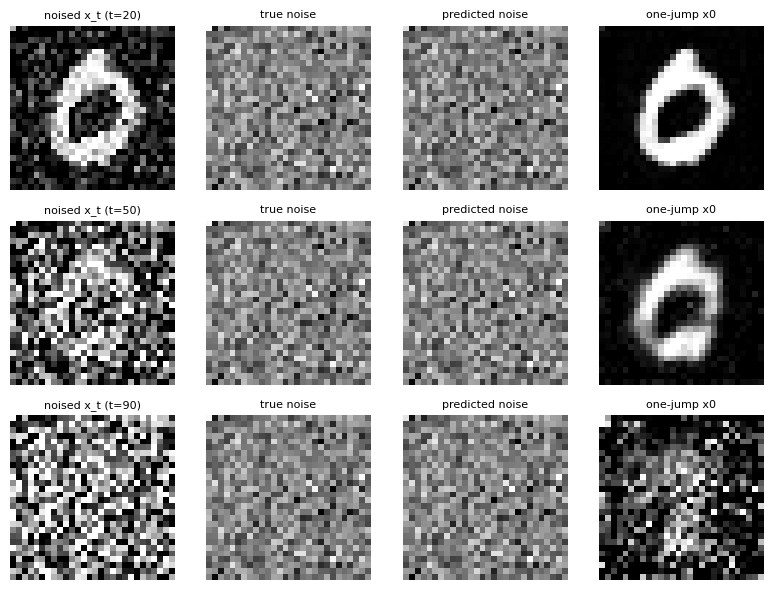

In [9]:
x0 = x_test[3:4]
noise = rng.standard_normal(x0.shape).astype("float32")
rows = []
for t in [20, 50, 90]:
    xt = q_sample(x0, np.array([t]), noise)
    nh = denoiser.predict([xt, TEMB[[t]]], verbose=0)
    ab = alpha_bar[t - 1]
    x0h = np.clip((xt - np.sqrt(1 - ab) * nh) / np.sqrt(ab), -1, 1)
    rows.append((t, xt[0, :, :, 0], noise[0, :, :, 0], nh[0, :, :, 0], x0h[0, :, :, 0]))
    print(f"t = {t}: noise MSE {np.mean((nh - noise) ** 2):.3f}   one-jump x0 error (MSE) {np.mean((x0h - x0) ** 2):.3f}")

plt.figure(figsize=(8, 6))
titles = ["noised x_t", "true noise", "predicted noise", "one-jump x0"]
for r, (t, *imgs) in enumerate(rows):
    for c, img in enumerate(imgs):
        ax = plt.subplot(3, 4, r * 4 + c + 1)
        ax.imshow(img, cmap="gray", vmin=-1 if c != 1 and c != 2 else -3, vmax=1 if c != 1 and c != 2 else 3)
        ax.axis("off"); ax.set_title(f"{titles[c]} (t={t})" if c == 0 else titles[c], fontsize=8)
plt.tight_layout(); plt.show()

### Why we see this

At t = 20 the one-jump guess is a decent digit. At t = 90 it is a **blur**: many different digits could have
produced that noisy picture, and under squared error the best single answer is their average, the same
hedging that made the autoencoder of Chapter 27 blurry. Diffusion's trick is to never trust the big leap: it
takes a small step towards the guess, adds back a little fresh noise, and asks again. Each small step only has
to be right about a little, and the many small decisions add up to one sharp digit.

---
## Step 10 - Sample: start from static, take 100 small steps back

The reverse step (the DDPM rule): remove the predicted noise with the right scaling, then add a small amount of
new noise (none on the last step):

`x_{t-1} = (x_t - beta_t / sqrt(1 - alpha_bar_t) * noise_hat) / sqrt(alpha_t) + sqrt(beta_t) * z`

> **Predict:** how many of 16 samples will you recognise as a digit? Write a number.

100 reverse steps for 16 digits: 3.4s


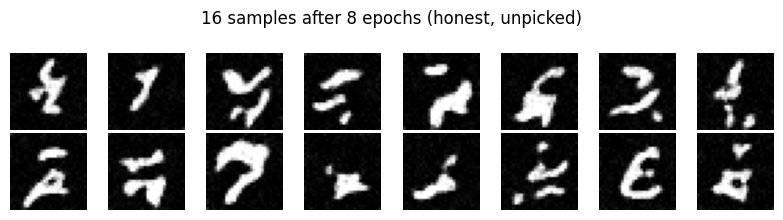

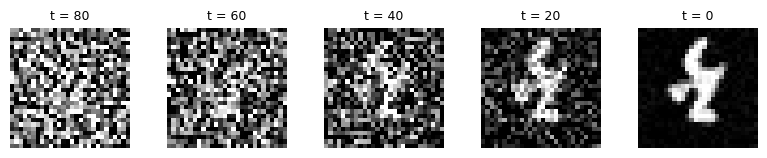

share of 'ink' pixels: samples 14.5%   real digits 12.4%


In [10]:
def sample(n=16, keep_every=None, seed=0):
    g = np.random.default_rng(seed)
    x = g.standard_normal((n, 28, 28, 1)).astype("float32")
    frames = {}
    for t in range(T, 0, -1):
        temb = np.repeat(TEMB[[t]], n, axis=0)
        nh = denoiser([x, temb], training=False).numpy()
        x = (x - betas[t - 1] / np.sqrt(1 - alpha_bar[t - 1]) * nh) / np.sqrt(alphas[t - 1])
        if t > 1:
            x = x + np.sqrt(betas[t - 1]) * g.standard_normal(x.shape).astype("float32")
        if keep_every and (t - 1) % keep_every == 0:
            frames[t - 1] = x[0, :, :, 0].copy()
    return np.clip(x, -1, 1), frames

t_s = time.time()
samples, frames = sample(16, keep_every=20, seed=1)
print(f"100 reverse steps for 16 digits: {time.time() - t_s:.1f}s")
plt.figure(figsize=(8, 2.2))
for i in range(16):
    ax = plt.subplot(2, 8, i + 1); ax.imshow(samples[i, :, :, 0], cmap="gray", vmin=-1, vmax=1); ax.axis("off")
plt.suptitle("16 samples after 8 epochs (honest, unpicked)"); plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 1.6))
for i, t in enumerate(sorted(frames, reverse=True)):
    ax = plt.subplot(1, len(frames), i + 1); ax.imshow(frames[t], cmap="gray", vmin=-1, vmax=1)
    ax.axis("off"); ax.set_title(f"t = {t}", fontsize=9)
plt.tight_layout(); plt.show()

ink = (samples > 0).mean(axis=(1, 2, 3))
real_ink = (x_test > 0).mean(axis=(1, 2, 3))
print(f"share of 'ink' pixels: samples {ink.mean():.1%}   real digits {real_ink.mean():.1%}")

### Why we see this

Shapes appear out of the static: strokes, hooks and loops, about the right amount of ink on a black background
(14.5% ink pixels in our run against 12.4% for real digits). After eight short epochs only two or three samples
could pass for a digit (a 1, a 7, a 6); the rest are stroke fragments no one would name. That is honest: the
network is about 300,000 parameters and has seen 96,000 noisy pictures. The reverse trajectory shows the order
of decisions: the rough blob of the shape is settled early (large t), the clean strokes only in the last
steps. Also notice the cost: **100 network calls** per batch of samples, where a GAN would need one. Sampling
speed is diffusion's weak spot, and why DDIM, distillation and consistency models exist.

---
## Step 11 - A different family: a GAN on a ring of 8 blobs

Real data: 8 small Gaussian blobs (standard deviation 0.05) evenly spaced on a circle of radius 2. A 2-D
problem lets us *see* everything the generator does.

> **Predict:** a well-trained generator puts about what share of its points near each blob?

In [11]:
K_MODES, RADIUS, STD = 8, 2.0, 0.05
centres = np.array([[RADIUS * np.cos(2 * np.pi * k / K_MODES), RADIUS * np.sin(2 * np.pi * k / K_MODES)]
                    for k in range(K_MODES)], dtype="float32")

def real_batch(n, g=rng):
    k = g.integers(0, K_MODES, size=n)
    return (centres[k] + STD * g.standard_normal((n, 2))).astype("float32")

def coverage(points, radius=0.25):
    """Share of points near some blob ('quality'), and how many blobs get at least 2% of points ('diversity')."""
    d = np.linalg.norm(points[:, None, :] - centres[None, :, :], axis=2)
    nearest, dist = d.argmin(axis=1), d.min(axis=1)
    good = dist < radius
    counts = np.bincount(nearest[good], minlength=K_MODES)
    return good.mean(), int(np.sum(counts >= 0.02 * len(points))), counts

print("centres:\n", centres.round(3))
q, m, _ = coverage(real_batch(2000))
print(f"real data: {q:.0%} of points near a blob, {m} of 8 blobs covered")

centres:
 [[ 2.     0.   ]
 [ 1.414  1.414]
 [ 0.     2.   ]
 [-1.414  1.414]
 [-2.     0.   ]
 [-1.414 -1.414]
 [-0.    -2.   ]
 [ 1.414 -1.414]]
real data: 100% of points near a blob, 8 of 8 blobs covered


---
## Step 12 - Generator and discriminator

Both are small MLPs. The generator maps 8 random numbers to a 2-D point. The discriminator maps a 2-D point to
one logit: "real" if large, "fake" if small.

> **Predict:** the parameter count of each (Dense: (in + 1) × out).

In [12]:
Z_DIM = 8

def make_gan():
    gen = keras.Sequential([layers.Input(shape=(Z_DIM,)),
                            layers.Dense(64, activation="relu"), layers.Dense(64, activation="relu"),
                            layers.Dense(2)], name="generator")
    disc = keras.Sequential([layers.Input(shape=(2,)),
                             layers.Dense(64), layers.LeakyReLU(0.2), layers.Dense(64), layers.LeakyReLU(0.2),
                             layers.Dense(1)], name="discriminator")
    return gen, disc

gen, disc = make_gan()
assert gen.count_params() == (8 + 1) * 64 + (64 + 1) * 64 + (64 + 1) * 2 == 4866
assert disc.count_params() == (2 + 1) * 64 + (64 + 1) * 64 + (64 + 1) * 1 == 4417
print("generator:", gen.count_params(), " discriminator:", disc.count_params())

generator: 4866  discriminator: 4417


---
## Step 13 - The adversarial loop

Each step: (1) the discriminator learns to say "real" to real points and "fake" to generated ones;
(2) the generator learns to make the discriminator say "real" to its points (the "non-saturating" loss used in
practice). `fit` cannot do this, so we write the loop with `GradientTape` (Chapter 30). We wrap it in a
function so that Step 13b can rerun it with one thing changed.

> **Predict:** will the generator cover all 8 blobs after 3,000 steps? Will the two loss columns tell you?

step  250  D loss 1.282  G loss 0.896  near a blob   8%  blobs covered 1/8


step  500  D loss 1.346  G loss 0.812  near a blob   4%  blobs covered 0/8


step  750  D loss 1.340  G loss 0.719  near a blob   4%  blobs covered 0/8


step 1000  D loss 1.225  G loss 0.790  near a blob   7%  blobs covered 0/8


step 1250  D loss 1.184  G loss 0.861  near a blob  28%  blobs covered 8/8


step 1500  D loss 1.233  G loss 0.822  near a blob  57%  blobs covered 8/8


... (2 outputs left out)

step 2250  D loss 1.247  G loss 0.869  near a blob  81%  blobs covered 7/8


step 2500  D loss 1.265  G loss 0.825  near a blob  84%  blobs covered 8/8


step 2750  D loss 1.283  G loss 0.861  near a blob  85%  blobs covered 8/8


step 3000  D loss 1.293  G loss 0.820  near a blob  88%  blobs covered 7/8
GAN trained in 5s;  points per blob at the end: [125 140  94  98 121 126 152  19]


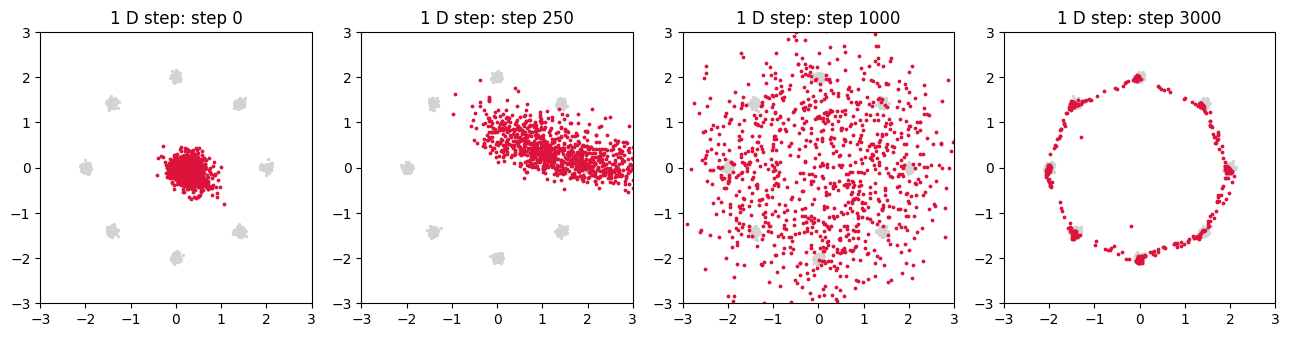

In [13]:
bce = keras.losses.BinaryCrossentropy(from_logits=True)
BATCH, STEPS, SNAP = 256, 3000, [0, 250, 1000, 3000]

def train_gan(d_steps=1, lr=1e-3, seed=29, verbose=True):
    keras.utils.set_random_seed(seed)
    g_rng = np.random.default_rng(seed)               # its own data stream: runs are repeatable
    gen, disc = make_gan()
    g_opt, d_opt = keras.optimizers.Adam(lr, beta_1=0.5), keras.optimizers.Adam(lr, beta_1=0.5)

    @tf.function(autograph=False)
    def d_step(real):
        z = tf.random.normal((BATCH, Z_DIM))
        with tf.GradientTape() as tape:
            lr_, lf = disc(real, training=True), disc(gen(z, training=True), training=True)
            d_loss = bce(tf.ones_like(lr_), lr_) + bce(tf.zeros_like(lf), lf)
        d_opt.apply_gradients(zip(tape.gradient(d_loss, disc.trainable_variables), disc.trainable_variables))
        return d_loss

    @tf.function(autograph=False)
    def g_step():
        z = tf.random.normal((BATCH, Z_DIM))
        with tf.GradientTape() as tape:
            lf = disc(gen(z, training=True), training=True)
            g_loss = bce(tf.ones_like(lf), lf)              # "make the detective say real"
        g_opt.apply_gradients(zip(tape.gradient(g_loss, gen.trainable_variables), gen.trainable_variables))
        return g_loss

    z_fixed = tf.random.normal((1000, Z_DIM), seed=seed)
    snaps, log = {0: gen(z_fixed).numpy()}, []
    for step in range(1, STEPS + 1):
        for _ in range(d_steps):
            d_l = d_step(tf.constant(real_batch(BATCH, g_rng)))
        g_l = g_step()
        if step % 250 == 0:
            q, m, _ = coverage(gen(z_fixed).numpy())
            log.append((step, float(d_l), float(g_l), q, m))
            if verbose:
                print(f"step {step:4d}  D loss {float(d_l):.3f}  G loss {float(g_l):.3f}  "
                      f"near a blob {q:4.0%}  blobs covered {m}/8")
        if step in SNAP:
            snaps[step] = gen(z_fixed).numpy()
    return snaps, log

def show_snaps(snaps, title):
    fig, axes = plt.subplots(1, len(SNAP), figsize=(13, 3.2))
    for ax, s in zip(axes, SNAP):
        ax.scatter(*real_batch(1000).T, s=2, c="lightgrey"); ax.scatter(*snaps[s].T, s=3, c="crimson")
        ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal"); ax.set_title(f"{title}: step {s}")
    plt.tight_layout(); plt.show()

t_g = time.time()
snaps, log = train_gan(d_steps=1)
print(f"GAN trained in {time.time() - t_g:.0f}s;  points per blob at the end:", coverage(snaps[STEPS])[2])
show_snaps(snaps, "1 D step")

### Why we see this

Read your own printout, because GANs differ from run to run. In our run the generator first squeezed its
points into a small clump that matched no blob (0 of 8 covered from step 500 to 1,000), then spread out, and
by step 1,250 it reached all 8. At the end 88% of its points sat close to a blob, fairly evenly, except that one
blob had only 19 of 1,000 points, just under our 2% bar, so the last line says 7 of 8. Now look at the loss
columns: they hover in the same narrow band (D about 1.2 to 1.35, G about 0.7 to 0.95) when 0 blobs are covered
and when 8 are. A GAN's losses are scores in a game against a moving opponent, not a measure of quality. To
know how a GAN is doing you must look at samples or measure coverage, as we did here.

---
## Step 13b - A stronger detective

A common instinct: "the discriminator is the teacher, so make it stronger". Train it **5 times** for every
generator step, everything else unchanged. One run proves little with GANs, so we compare both settings on
the same three seeds (about a minute).

> **Predict:** more blobs covered, fewer, or the same? Higher or lower share of points on a blob?

seed 29  D steps 1:  blobs covered 7/8   near a blob  88%   points per blob [125 140  94  98 121 126 152  19]


seed 29  D steps 5:  blobs covered 8/8   near a blob  91%   points per blob [182  26 201  47 192  38 169  56]


seed 30  D steps 1:  blobs covered 8/8   near a blob  89%   points per blob [ 93 108  89 115 113 132 128 110]


seed 30  D steps 5:  blobs covered 3/8   near a blob  95%   points per blob [341 398   3   0   5   0   0 201]


seed 31  D steps 1:  blobs covered 8/8   near a blob  87%   points per blob [107 115 115 103 116 124  99  91]


seed 31  D steps 5:  blobs covered 6/8   near a blob  92%   points per blob [  3 105  87   3 127 198 230 164]
six GANs trained in 59s


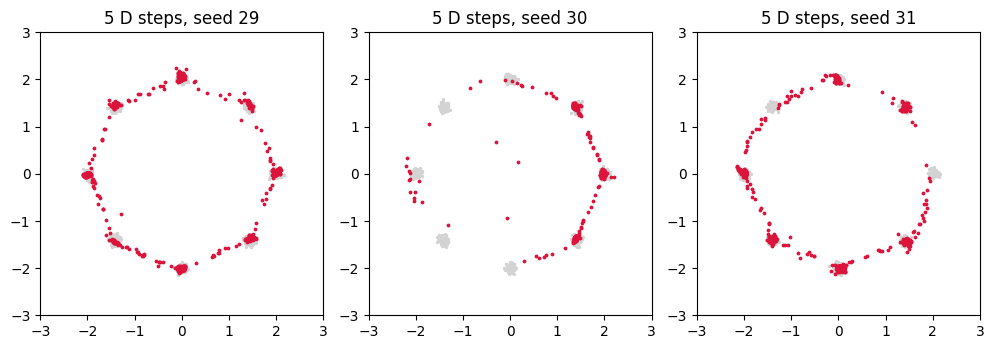

In [14]:
t_g = time.time()
results = {}
for seed in [29, 30, 31]:
    for d in [1, 5]:
        sn, lg = train_gan(d_steps=d, seed=seed, verbose=False)
        results[(seed, d)] = (sn[STEPS], lg)
        q, m, counts = coverage(sn[STEPS])
        print(f"seed {seed}  D steps {d}:  blobs covered {m}/8   near a blob {q:4.0%}   points per blob {counts}")
print(f"six GANs trained in {time.time() - t_g:.0f}s")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, seed in zip(axes, [29, 30, 31]):
    pts = results[(seed, 5)][0]
    ax.scatter(*real_batch(1000).T, s=2, c="lightgrey"); ax.scatter(*pts.T, s=3, c="crimson")
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal"); ax.set_title(f"5 D steps, seed {seed}")
plt.tight_layout(); plt.show()

### Why we see this

In our run the one-step GAN covered 7, 8 and 8 blobs over the three seeds, with 87 to 89% of points on a
blob. The five-step GAN put **more** of its points on blobs (91 to 95%) but covered 8, **3** and 6 blobs, and
even its 8-blob run was lopsided (about 190 points on four blobs, 26 to 56 on the other four). That is
**mode collapse**, partial here: sharper samples, less variety, the trilemma in miniature. An over-strong
detective gives the forger a steep, narrow signal ("go *there*"), and the forger piles its points onto whatever
region works today. Nothing in the loss values warns you. The cures (the stabilisers in Chapter 29) all try to
keep the detective's feedback smooth and informative everywhere: Wasserstein losses with a gradient penalty,
spectral normalisation, balanced learning rates.

---
## Step 14 - Classifier-free guidance, as one line of arithmetic

A text-to-image model is trained so that it can predict the noise **with** the prompt and, with the prompt
dropped (about 10% of training examples), **without** it. At sampling time it makes both predictions and
exaggerates the difference:

`noise_guided = noise_uncond + w * (noise_cond - noise_uncond)`

w = 1 is the plain conditional model; w around 5 to 8 is typical for images; very large w pushes the sample to
over-saturated, distorted extremes. We have no labels in our denoiser, so here is the arithmetic on three
made-up pixel values.

> **Predict:** what happens to a pixel where the two predictions agree?

In [15]:
noise_uncond = np.array([0.20, -0.50, 1.00])
noise_cond = np.array([0.30, -0.10, 1.00])
for w in [0, 1, 3, 7.5]:
    print(f"w = {w:4}:", (noise_uncond + w * (noise_cond - noise_uncond)).round(2))
print(f"Total lab time: {time.time() - T0:.0f}s")

w =    0: [ 0.2 -0.5  1. ]
w =    1: [ 0.3 -0.1  1. ]
w =    3: [0.5 0.7 1. ]
w =  7.5: [0.95 2.5  1.  ]
Total lab time: 210s


### Why we see this

Where the two predictions agree (the third pixel), guidance changes nothing. Where they disagree, guidance
multiplies the disagreement: it pushes the sample further in the direction that "the prompt" pulls it. Small w:
faithful to the data but loosely following the prompt. Large w: follows the prompt hard, at the cost of
variety and, eventually, realism. It costs two network calls per step (or one call on a doubled batch).

---
## Trials: change one thing at a time

Change one setting, **write your prediction first**, rerun the steps named, and fill in the last column.

| # | Change | Rerun | Predict | Observe |
|---|---|---|---|---|
| 1 | `betas` end 0.12 → 0.03 (Step 3) | 3, 4 | What is left of the digit at t = 100? Can sampling still start from pure noise? | |
| 2 | `EPOCHS` 8 → 30 | 7 to 10 | How much does the loss fall? How many of 16 samples now read as digits? | |
| 3 | Remove the time input (feed zeros as `t_embedding`) | 6 to 10 | Loss higher or lower? What do samples look like? | |
| 4 | Sample with every second step only (skip the odd t) using the same rule | 10 | Faster, but what breaks, and why? | |
| 5 | Remove the `+ sqrt(beta_t) * z` term in sampling | 10 | Sharper digits, or smooth grey blobs? | |
| 6 | GAN learning rates 1e-3 → 1e-4 | 13 | Slower, but more or fewer blobs covered? | |
| 7 | GAN `Z_DIM` 8 → 1 | 12, 13 | Can a 1-number input reach 8 separate blobs cleanly? | |
| 8 | Rerun Step 13b with seeds 1, 2, 3 | 13b | Same number of blobs every time? What does that say about judging a GAN from one run? | |

## Exercises

1. **Cosine schedule.** Replace the linear betas with alpha_bar_t = cos²(((t/T) + 0.008) / 1.008 · π/2),
   normalised so it starts at 1. Plot the two SNR curves in dB on one chart. Where does each spend its steps?
2. **Predict x0 instead of the noise.** Change the target of the denoiser to the clean digit and convert in
   sampling. Compare the samples after the same 8 epochs.
3. **A conditional denoiser.** Add the digit label as a third input (an `Embedding(10, 32)` added to the time
   embedding). Drop the label 10% of the time (use an 11th "no label" index), then implement classifier-free
   guidance from Step 14 and sample rows of 3s and 8s with w = 0, 1, 3.
4. **Nearest neighbour check.** For each of your 16 samples, find the closest training digit in pixel space.
   Are any samples near-copies? What would you conclude if they were?
5. **Fix mode collapse.** Try one change at a time on the GAN: a smaller generator learning rate, label
   smoothing (real target 0.9), or a minibatch-diversity feature. Record blobs covered over 5 seeds each.
6. **A GAN on digits.** Replace the toy data with MNIST and the MLPs with a tiny DCGAN (Conv2DTranspose
   generator, strided Conv2D discriminator). After 3 minutes of training, compare with Step 10's samples.

## Cheat sheet

| Idea | One line |
|---|---|
| Forward process | x_t = sqrt(alpha_bar_t) · x_0 + sqrt(1 − alpha_bar_t) · noise; jump to any t |
| SNR | alpha_bar / (1 − alpha_bar); falls from thousands to near zero over the schedule |
| Training | random t, random noise, predict the noise, MSE; "always zero" scores 1.0 |
| Denoiser | a U-Net with the step number added as an embedding; here 299,297 parameters |
| One jump vs many | the one-jump guess at large t is a blur (an average); small steps stay sharp |
| Sampling cost | T network calls per batch (here 100); GANs need one |
| GAN | two players, alternating updates, custom loop; losses do not measure quality |
| Mode collapse | the generator covers some modes and ignores the rest; measure coverage |
| Guidance | uncond + w · (cond − uncond); w ≈ 5–8 for images, too large distorts |